In [1]:
import cv2
import os
import random
import gc
import pywt

import numpy as np
import scipy.io as sio
import scipy.misc as misc
import tensorflow as tf
import matplotlib.pyplot as plt
%matplotlib inline

from keras import backend as K
from keras.layers import Add, Activation, BatchNormalization
from keras.layers import Concatenate, Conv2D, Input, Layer
from keras.models import Model
from keras.optimizers import Adam
from keras.callbacks import LearningRateScheduler, ModelCheckpoint

from scipy import ndimage
from scipy import signal
from scipy.ndimage import zoom
from scipy.ndimage import correlate
from scipy.special import erfinv

from sklearn.decomposition import PCA as princomp
from skimage.transform import resize

from cv2.ximgproc import guidedFilter

from tqdm import tqdm

from PIL import Image

C:\Users\Monia\anaconda3\envs\datafusion\Lib\site-packages\h5py\__init__.py:36: UserWarning: h5py is running against HDF5 1.14.3 when it was built against 1.14.2, this may cause problems
  _warn(("h5py is running against HDF5 {0} when it was built against {1}, "


In [2]:
'''loading data'''
original_msi = np.load("D:/geoinformatics/MajorProject/main/npyfiles/rgb_npy/WG_RGB_BLOCK_1_1.npy")
original_msi = np.transpose(original_msi, (1, 2, 0))
original_pan = np.load("D:/geoinformatics/MajorProject/main/npyfiles/pan_npy/WG_PAN_BLOCK_1_1.npy")
original_pan = np.transpose(original_pan, (1, 2, 0))

In [3]:
print(original_msi.shape , "&", original_msi.dtype)
print(original_pan.shape , "&", original_pan.dtype)

(512, 512, 4) & uint16
(1024, 1024, 1) & uint16


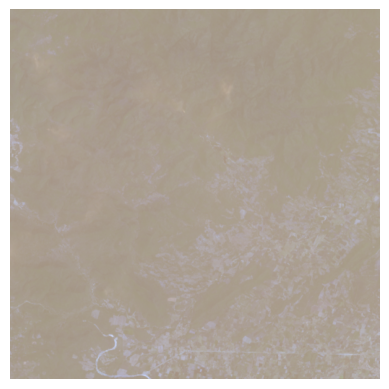

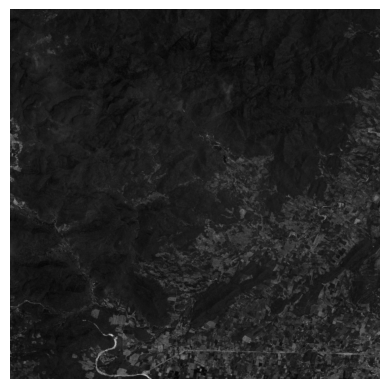

In [4]:
# Extract the RGB channels
rgb_image = original_msi[..., :3]

# Since the image is in uint16 format, we need to normalize it for display
# Normalize to range [0, 1] for matplotlib
rgb_image = rgb_image.astype(np.float32) / np.max(rgb_image)

# Display the RGB image
plt.imshow(rgb_image)
plt.axis('off')  # Hide the axes
plt.show()

plt.axis("off")
plt.imshow(original_pan, cmap= 'gray')

In [5]:
'''normalization'''
max_patch, min_patch = np.max(original_msi, axis=(0,1)), np.min(original_msi, axis=(0,1))
original_msi = np.float32(original_msi-min_patch) / (max_patch - min_patch)

max_patch, min_patch = np.max(original_pan, axis=(0,1)), np.min(original_pan, axis=(0,1))
original_pan = np.float32(original_pan-min_patch) / (max_patch - min_patch)

In [6]:
print(original_msi.shape , "&", original_msi.dtype)
print(original_pan.shape , "&", original_pan.dtype)

(512, 512, 4) & float32
(1024, 1024, 1) & float32


In [7]:
gt = np.uint8(np.resize(original_msi, (1024, 1024, 4)))

In [8]:
print(gt.shape , "&", gt.dtype)

(1024, 1024, 4) & uint8


In [9]:
print('ms shape: ', original_msi.shape, 'pan shape: ', original_pan.shape)

'''setting save parameters'''
save_images = True
#: = [0, 1, 2]#BGR-NIR for GF2
save_dir= "D:/geoinformatics/MajorProject/main/output_tif/1_1/"
if save_images and (not os.path.isdir(save_dir)):
    os.makedirs(save_dir)

ms shape:  (512, 512, 4) pan shape:  (1024, 1024, 1)


In [10]:
def upsample_bicubic(image, ratio):
    
    h,w,c = image.shape
    re_image = cv2.resize(image, (w*ratio, h*ratio), interpolation=cv2.INTER_CUBIC)
    
    return re_image

In [11]:
def upsample_interp23(image, ratio):

    image = np.transpose(image, (2, 0, 1))
    
    b,r,c = image.shape

    CDF23 = 2*np.array([0.5, 0.305334091185, 0, -0.072698593239, 0, 0.021809577942, 0, -0.005192756653, 0, 0.000807762146, 0, -0.000060081482])
    d = CDF23[::-1] 
    CDF23 = np.insert(CDF23, 0, d[:-1])
    BaseCoeff = CDF23
    
    first = 1
    for z in range(1,int(np.log2(ratio))+1):
        I1LRU = np.zeros((b, 2**z*r, 2**z*c))
        if first:
            I1LRU[:, 1:I1LRU.shape[1]:2, 1:I1LRU.shape[2]:2]=image
            first = 0
        else:
            I1LRU[:,0:I1LRU.shape[1]:2,0:I1LRU.shape[2]:2]=image
        
        for ii in range(0,b):
            t = I1LRU[ii,:,:]
            for j in range(0,t.shape[0]):
                t[j,:]=ndimage.correlate(t[j,:],BaseCoeff,mode='wrap')
            for k in range(0,t.shape[1]):
                t[:,k]=ndimage.correlate(t[:,k],BaseCoeff,mode='wrap')
            I1LRU[ii,:,:]=t
        image = I1LRU
        
    re_image=np.transpose(I1LRU, (1, 2, 0))
        
    return re_image

In [12]:
def resize_image(image, ratio, interpolation=Image.BICUBIC):
    """
    Resize an image using Pillow.
    """
    pil_image = Image.fromarray(image)
    new_size = (int(image.shape[1] / ratio), int(image.shape[0] / ratio))
    resized_image = pil_image.resize(new_size, interpolation)
    return np.array(resized_image, dtype=np.float64)

In [13]:
def downgrade_images(I_MS, I_PAN, ratio, sensor='landsat8'):
    """
    Downgrade MS and PAN by a ratio factor with given sensor's gains.
    """
    I_MS = np.double(I_MS)
    I_PAN = np.double(I_PAN)
    
    I_MS = np.transpose(I_MS, (2, 0, 1))
    I_PAN = np.squeeze(I_PAN)
    
    ratio = np.double(ratio)
    flag_PAN_MTF = 0
    
    if sensor == 'landsat8':
        flag_resize_new = 2
        GNyq = np.asarray([0.29, 0.26, 0.26, 0.25], dtype='float32')  # Band Order: B, G, R, NIR
        GNyqPan = 0.23
    else:
        '''the default way'''
        flag_resize_new = 1
    
    '''the default downgrading method is gaussian'''
    if flag_resize_new == 1:
        sig = (1 / (2 * (2.772587) / ratio**2))**0.5
        kernel = np.multiply(cv2.getGaussianKernel(9, sig), cv2.getGaussianKernel(9, sig).T)
        
        t = []
        for i in range(I_MS.shape[0]):
            temp = signal.convolve2d(I_MS[i, :, :], kernel, mode='same', boundary='wrap')
            temp = temp[0::int(ratio), 0::int(ratio)]
            temp = np.expand_dims(temp, 0)
            t.append(temp)
            
        I_MS_LR = np.concatenate(t, axis=0)
        
        I_PAN_LR = signal.convolve2d(I_PAN, kernel, mode='same', boundary='wrap')
        I_PAN_LR = I_PAN_LR[0::int(ratio), 0::int(ratio)]
        
    elif flag_resize_new == 2:
        N = 41
        I_MS_LP = np.zeros(I_MS.shape)
        fcut = 1 / ratio
        
        for j in range(I_MS.shape[0]):
            # FIR filter with window method
            alpha = np.sqrt(((N - 1) * (fcut / 2))**2 / (-2 * np.log(GNyq[j])))
            H = gaussian2d(N, alpha)
            Hd = H / np.max(H)
            w = kaiser2d(N, 0.5)
            h = fir_filter_wind(Hd, w)
            I_MS_LP[j, :, :] = ndimage.correlate(I_MS[j, :, :], np.real(h), mode='nearest')
        
        if flag_PAN_MTF == 1:
            # FIR filter with window method
            alpha = np.sqrt(((N - 1) * (fcut / 2))**2 / (-2 * np.log(GNyqPan)))
            H = gaussian2d(N, alpha)
            Hd = H / np.max(H)
            h = fir_filter_wind(Hd, w)
            I_PAN = ndimage.correlate(I_PAN, np.real(h), mode='nearest')
            I_PAN_LR = I_PAN[int(ratio / 2):-1:int(ratio), int(ratio / 2):-1:int(ratio)]
        else:
            # Bicubic resize using PIL
            I_PAN_pad = np.pad(I_PAN, int(2 * ratio), 'symmetric')
            I_PAN_LR = resize_image(I_PAN_pad, ratio)
            I_PAN_LR = I_PAN_LR[2:-2, 2:-2]
            
        I_MS_LR = I_MS_LP[:, int(ratio / 2):-1:int(ratio), int(ratio / 2):-1:int(ratio)]     
    
    I_MS_LR = np.transpose(I_MS_LR, (1, 2, 0))
    I_PAN_LR = np.expand_dims(I_PAN_LR, -1)
    
    return I_MS_LR, I_PAN_LR

In [14]:
def sam(img1, img2):
    """SAM for 3D image, shape (H, W, C); uint or float[0, 1]"""
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    
    if img1.ndim != 3 or img1.shape[2] <= 1:
        raise ValueError('Images must be 3D with more than 1 channel.')

    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)

    inner_product = np.sum(img1_ * img2_, axis=2)
    img1_spectral_norm = np.sqrt(np.sum(img1_**2, axis=2))
    img2_spectral_norm = np.sqrt(np.sum(img2_**2, axis=2))

    # Avoid division by zero
    norm_product = img1_spectral_norm * img2_spectral_norm
    norm_product = np.where(norm_product == 0, np.finfo(np.float64).eps, norm_product)

    cos_theta = np.clip(inner_product / norm_product, -1.0, 1.0)
    
    return np.mean(np.arccos(cos_theta))

In [15]:
def psnr(img1, img2, dynamic_range=255):
    """PSNR metric, img uint8 if 225; uint16 if 2047"""
    if not  img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    mse = np.mean((img1_ - img2_)**2)
    if mse <= 1e-10:
        return np.inf
    return 20 * np.log10(dynamic_range / (np.sqrt(mse) + np.finfo(np.float64).eps))

In [16]:
def scc(img1, img2):
    """SCC for 2D (H, W)or 3D (H, W, C) image; uint or float[0, 1]"""
    if not  img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    if img1_.ndim == 2:
        return np.corrcoef(img1_.reshape(1, -1), img2_.rehshape(1, -1))[0, 1]
    elif img1_.ndim == 3:
        #print(img1_[..., i].reshape[1, -1].shape)
        #test = np.corrcoef(img1_[..., i].reshape[1, -1], img2_[..., i].rehshape(1, -1))
        #print(type(test))
        ccs = [np.corrcoef(img1_[..., i].reshape(1, -1), img2_[..., i].reshape(1, -1))[0, 1]
               for i in range(img1_.shape[2])]
        return np.mean(ccs)
    else:
        raise ValueError('Wrong input image dimensions.')

In [17]:
def _qindex(img1, img2, block_size=8):
    """Q-index for 2D (one-band) image, shape (H, W); uint or float [0, 1]"""
    assert block_size > 1, 'block_size shold be greater than 1!'
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    window = np.ones((block_size, block_size)) / (block_size**2)
    # window_size = block_size**2
    # filter, valid
    pad_topleft = int(np.floor(block_size/2))
    pad_bottomright = block_size - 1 - pad_topleft
    mu1 = cv2.filter2D(img1_, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright]
    mu2 = cv2.filter2D(img2_, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright]
    mu1_sq = mu1**2
    mu2_sq = mu2**2
    mu1_mu2 = mu1 * mu2
    
    sigma1_sq = cv2.filter2D(img1_**2, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright] - mu1_sq
    sigma2_sq = cv2.filter2D(img2_**2, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright] - mu2_sq
#    print(mu1_mu2.shape)
    #print(sigma2_sq.shape)
    sigma12 = cv2.filter2D(img1_ * img2_, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright] - mu1_mu2

    # all = 1, include the case of simga == mu == 0
    qindex_map = np.ones(sigma12.shape)
    # sigma == 0 and mu != 0
    
#    print(np.min(sigma1_sq + sigma2_sq), np.min(mu1_sq + mu2_sq))
    
    idx = ((sigma1_sq + sigma2_sq) < 1e-8) * ((mu1_sq + mu2_sq) >1e-8)
    qindex_map[idx] = 2 * mu1_mu2[idx] / (mu1_sq + mu2_sq)[idx]
    # sigma !=0 and mu == 0
    idx = ((sigma1_sq + sigma2_sq) >1e-8) * ((mu1_sq + mu2_sq) < 1e-8)
    qindex_map[idx] = 2 * sigma12[idx] / (sigma1_sq + sigma2_sq)[idx]
    # sigma != 0 and mu != 0
    idx = ((sigma1_sq + sigma2_sq) >1e-8) * ((mu1_sq + mu2_sq) >1e-8)
    qindex_map[idx] =((2 * mu1_mu2[idx]) * (2 * sigma12[idx])) / (
        (mu1_sq + mu2_sq)[idx] * (sigma1_sq + sigma2_sq)[idx])
    
#    print(np.mean(qindex_map))
    
#    idx = ((sigma1_sq + sigma2_sq) == 0) * ((mu1_sq + mu2_sq) != 0)
#    qindex_map[idx] = 2 * mu1_mu2[idx] / (mu1_sq + mu2_sq)[idx]
#    # sigma !=0 and mu == 0
#    idx = ((sigma1_sq + sigma2_sq) != 0) * ((mu1_sq + mu2_sq) == 0)
#    qindex_map[idx] = 2 * sigma12[idx] / (sigma1_sq + sigma2_sq)[idx]
#    # sigma != 0 and mu != 0
#    idx = ((sigma1_sq + sigma2_sq) != 0) * ((mu1_sq + mu2_sq) != 0)
#    qindex_map[idx] =((2 * mu1_mu2[idx]) * (2 * sigma12[idx])) / (
#        (mu1_sq + mu2_sq)[idx] * (sigma1_sq + sigma2_sq)[idx])
    
    return np.mean(qindex_map)

In [18]:
def qindex(img1, img2, block_size=8):
    """Q-index for 2D (H, W) or 3D (H, W, C) image; uint or float [0, 1]"""
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    if img1.ndim == 2:
        return _qindex(img1, img2, block_size)
    elif img1.ndim == 3:
        qindexs = [_qindex(img1[..., i], img2[..., i], block_size) for i in range(img1.shape[2])]
        return np.array(qindexs).mean()
    else:
        raise ValueError('Wrong input image dimensions.')

In [19]:
def _ssim(img1, img2, dynamic_range=255):
    """SSIM for 2D (one-band) image, shape (H, W); uint8 if 225; uint16 if 2047"""
    C1 = (0.01 * dynamic_range)**2
    C2 = (0.03 * dynamic_range)**2
    
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    kernel = cv2.getGaussianKernel(11, 1.5)  # kernel size 11
    window = np.outer(kernel, kernel.transpose())
    
    mu1 = cv2.filter2D(img1_, -1, window)[5:-5, 5:-5]  # valid
    mu2 = cv2.filter2D(img2_, -1, window)[5:-5, 5:-5]
    mu1_sq = mu1**2
    mu2_sq = mu2**2
    mu1_mu2 = mu1 * mu2
    sigma1_sq = cv2.filter2D(img1_**2, -1, window)[5:-5, 5:-5] - mu1_sq
    sigma2_sq = cv2.filter2D(img2_**2, -1, window)[5:-5, 5:-5] - mu2_sq
    sigma12 = cv2.filter2D(img1_ * img2_, -1, window)[5:-5, 5:-5] - mu1_mu2
    
    ssim_map = ((2 * mu1_mu2 + C1) * (2 * sigma12 + C2)) / (
        (mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2))
    return ssim_map.mean()

In [20]:
def ssim(img1, img2, dynamic_range=255):
    """SSIM for 2D (H, W) or 3D (H, W, C) image; uint8 if 225; uint16 if 2047"""
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    if img1.ndim == 2:
        return _ssim(img1, img2, dynamic_range)
    elif img1.ndim == 3:
        ssims = [_ssim(img1[..., i], img2[..., i], dynamic_range) for i in range(img1.shape[2])]
        return np.array(ssims).mean()
    else:
        raise ValueError('Wrong input image dimensions.')


In [21]:
def ergas(img_fake, img_real, scale=4):
    """ERGAS for 2D (H, W) or 3D (H, W, C) image; uint or float [0, 1].
    scale = spatial resolution of PAN / spatial resolution of MUL, default 4."""
    if not img_fake.shape == img_real.shape:
        raise ValueError('Input images must have the same dimensions.')
    img_fake_ = img_fake.astype(np.float64)
    img_real_ = img_real.astype(np.float64)
    if img_fake_.ndim == 2:
        mean_real = img_real_.mean()
        mse = np.mean((img_fake_ - img_real_)**2)
        return 100 / scale * np.sqrt(mse / (mean_real**2 + np.finfo(np.float64).eps))
    elif img_fake_.ndim == 3:
        means_real = img_real_.reshape(-1, img_real_.shape[2]).mean(axis=0)
        mses = ((img_fake_ - img_real_)**2).reshape(-1, img_fake_.shape[2]).mean(axis=0)
        return 100 / scale * np.sqrt((mses / (means_real**2 + np.finfo(np.float64).eps)).mean())
    else:
        raise ValueError('Wrong input image dimensions.')

In [22]:
def gaussian2d(N, std):
    
    t=np.arange(-(N-1)/2,(N+2)/2)
    t1,t2=np.meshgrid(t,t)
    std=np.double(std)
    w = np.exp(-0.5*(t1/std)**2)*np.exp(-0.5*(t2/std)**2) 
    return w

In [23]:
def kaiser2d(N, beta):
    
    t=np.arange(-(N-1)/2,(N+1)/2)/np.double(N-1)
    t1,t2=np.meshgrid(t,t)
    t12=np.sqrt(t1*t1+t2*t2)
    w1=np.kaiser(N,beta)
    w=np.interp(t12,t,w1)
    w[t12>t[-1]]=0
    w[t12<t[0]]=0
    
    return w

In [24]:
def resize_window(w, target_shape):
    """
    Resize the window function to match the target shape.
    """
    factors = (target_shape[0] / w.shape[0], target_shape[1] / w.shape[1])
    resized_w = zoom(w, factors, mode='constant')
    return resized_w

In [25]:
def fir_filter_wind(Hd, w):
    """
    compute fir (finite impulse response) filter with window method
    Hd: desired freqeuncy response (2D)
    w: window (2D)
    """
    hd = np.rot90(np.fft.fftshift(np.rot90(Hd, 2)), 2)
    h = np.fft.fftshift(np.fft.ifft2(hd))
    h = np.rot90(h, 2)

    if h.shape != w.shape:
        w = resize_window(w, h.shape)
        print(f"Shape of w after resizing: {w.shape}")
    h = h * w
    h = h / np.sum(h)
    return h

In [26]:
def GNyq2win(GNyq, scale=2, N=41):
    """Generate a 2D convolutional window from a given GNyq
    GNyq: Nyquist frequency
    scale: spatial size of PAN / spatial size of MS
    """
    #fir filter with window method
    fcut = 1 / scale
    alpha = np.sqrt(((N - 1) * (fcut / 2))**2 / (-2 * np.log(GNyq)))
    H = gaussian2d(N, alpha)
    Hd = H / np.max(H)
    w = kaiser2d(N, 0.5)
    h = fir_filter_wind(Hd, w)
    return np.real(h)

In [27]:
def mtf_resize(img, satellite='landsat8', scale=2):
    # satellite GNyq
    scale = int(scale)
    if satellite == 'landsat8':
        GNyq = [0.29, 0.26, 0.26,0.25]  # Band Order: B,G,R,NIR
        GNyqPan = 0.23
    else:
        raise NotImplementedError('satellite: landsat 8')
    # lowpass
    img_ = img.squeeze()
    img_ = img_.astype(np.float64)
    if img_.ndim == 2:  # Pan
        H, W = img_.shape
        lowpass = GNyq2win(GNyqPan, scale = 2, N=41)
    elif img_.ndim == 3:  # MS
        H, W, _ = img.shape
        lowpass = [GNyq2win(gnyq, scale = 2, N=41) for gnyq in GNyq]
        lowpass = np.stack(lowpass, axis=-1)
    img_ = correlate(img_, lowpass, mode='nearest')
    # downsampling
    output_size = (H // scale, W // scale)
    img_ = cv2.resize(img_, dsize=output_size, interpolation=cv2.INTER_NEAREST)
    return img_

In [28]:
def D_lambda(img_fake, img_lm, block_size=32, p=1):
    """Spectral distortion
    img_fake, generated HRMS
    img_lm, LRMS"""
    assert img_fake.ndim == img_lm.ndim == 3, 'Images must be 3D!'
    H_f, W_f, C_f = img_fake.shape
    H_r, W_r, C_r = img_lm.shape
    assert C_f == C_r, 'Fake and lm should have the same number of bands!'
    # D_lambda
    Q_fake = []
    Q_lm = []
    for i in range(C_f):
        for j in range(i+1, C_f):
            # for fake
            band1 = img_fake[..., i]
            band2 = img_fake[..., j]
            Q_fake.append(_qindex(band1, band2, block_size=block_size))
            # for real
            band1 = img_lm[..., i]
            band2 = img_lm[..., j]
            Q_lm.append(_qindex(band1, band2, block_size=block_size))
    Q_fake = np.array(Q_fake)
    Q_lm = np.array(Q_lm)
    D_lambda_index = (np.abs(Q_fake - Q_lm) ** p).mean()
    return D_lambda_index ** (1/p)

In [29]:
def D_s(img_fake, img_lm, pan, satellite='landsat8', scale=2, block_size=32, q=1):
    """Spatial distortion
    img_fake, generated HRMS
    img_lm, LRMS
    pan, HRPan"""
    # fake and lm
    assert img_fake.ndim == img_lm.ndim == 3, 'MS images must be 3D!'
    H_f, W_f, C_f = img_fake.shape
    H_r, W_r, C_r = img_lm.shape
    print(f"H_f: {H_f}, W_f: {W_f}, H_r: {H_r}, W_r: {W_r}, scale: {scale}")
    assert H_f // H_r == W_f // W_r == scale, 'Spatial resolution should be compatible with scale'
    assert C_f == C_r, 'Fake and lm should have the same number of bands!'
    # fake and pan
    assert pan.ndim == 3, 'Panchromatic image must be 3D!'
    H_p, W_p, C_p = pan.shape
    assert C_p == 1, 'size of 3rd dim of Panchromatic image must be 1'
    assert H_f == H_p and W_f == W_p, "Pan's and fake's spatial resolution should be the same"
    # get LRPan, 2D
    pan_lr = mtf_resize(pan, satellite=satellite, scale=scale)
    #print(pan_lr.shape)
    # D_s
    Q_hr = []
    Q_lr = []
    for i in range(C_f):
        # for HR fake
        band1 = img_fake[..., i]
        band2 = pan[..., 0] # the input PAN is 3D with size=1 along 3rd dim
        #print(band1.shape)
        #print(band2.shape)
        Q_hr.append(_qindex(band1, band2, block_size=block_size))
        band1 = img_lm[..., i]
        band2 = pan_lr  # this is 2D
        #print(band1.shape)
        #print(band2.shape)
        Q_lr.append(_qindex(band1, band2, block_size=block_size))
    Q_hr = np.array(Q_hr)
    Q_lr = np.array(Q_lr)
    D_s_index = (np.abs(Q_hr - Q_lr) ** q).mean()
    return D_s_index ** (1/q)

In [30]:
def qnr(img_fake, img_lm, pan, satellite='landsat8', scale=2, block_size=32, p=1, q=1, alpha=1, beta=1):
    """QNR - No reference IQA"""
    D_lambda_idx = D_lambda(img_fake, img_lm, block_size, p)
    D_s_idx = D_s(img_fake, img_lm, pan, satellite, scale, block_size, q)
    QNR_idx = (1 - D_lambda_idx) ** alpha * (1 - D_s_idx) ** beta
    return QNR_idx

In [31]:
def ref_evaluate(pred, gt):
    #reference metrics
    c_psnr = psnr(pred, gt)
    c_ssim = ssim(pred, gt)
    c_sam = sam(pred, gt)
    c_ergas = ergas(pred, gt)
    c_scc = scc(pred, gt)
    c_q = qindex(pred, gt)

    return [c_psnr, c_ssim, c_sam, c_ergas, c_scc, c_q]

In [32]:
def no_ref_evaluate(pred, pan, hs):
    #no reference metrics
    c_D_lambda = D_lambda(pred, hs)
    c_D_s = D_s(pred, hs, pan)
    c_qnr = qnr(pred, hs, pan)
    
    return [c_D_lambda, c_D_s, c_qnr]

In [33]:
'''evaluating all methods'''
ref_results={}
ref_results.update({'metrics: ':'  PSNR,     SSIM,   SAM,    ERGAS,  SCC,    Q'})
no_ref_results={}
no_ref_results.update({'metrics: ':'  D_lamda, D_s,    QNR'})

In [34]:
def psnr_loss(y_true, y_pred):
    """Peak signal-to-noise ratio averaged over samples and channels."""
    mse = tf.reduce_mean(tf.square(tf.cast(y_true, tf.float32) * 255.0 - tf.cast(y_pred, tf.float32) * 255.0), axis=(-3, -2, -1))
    return tf.reduce_mean(20.0 * tf.math.log(255.0 / tf.sqrt(tf.cast(mse, tf.float32))) / tf.math.log(10.0))

In [35]:
def pnn_net(lrhs_size=(32, 32, 4), hrms_size = (32, 32, 1)):
    
    lrhs_inputs = Input(lrhs_size)
    hrms_inputs = Input(hrms_size)
    
    mixed = Concatenate()([lrhs_inputs, hrms_inputs])

    conv1 = Conv2D(64, (9, 9), strides=(1, 1), padding='same')(mixed)
    conv1 = Activation('relu')(conv1)
    
    conv2 = Conv2D(64, (9, 9), strides=(1, 1), padding='same')(conv1)
    conv2 = Activation('relu')(conv2)
    
    conv3 = Conv2D(32, (5, 5), strides=(1, 1), padding='same')(conv2)
    conv3 = Activation('relu')(conv3)

    # Adding more layers to increase complexity
    mixed1 = Conv2D(32, (3, 3), strides=(1, 1), padding='same', activation='relu')(conv3)
    mixed1 = Conv2D(32, (3, 3), strides=(1, 1), padding='same', activation='relu')(mixed1)
    
    c6 = Conv2D(lrhs_size[2], (5, 5), strides=(1, 1), padding='same', activation='relu', name='model1_last1')(mixed1)
    
    model = Model(inputs = [lrhs_inputs, hrms_inputs], outputs = c6)

    model.compile(optimizer=Adam(learning_rate=2e-4), loss='mse', metrics=[psnr_loss])
    
    model.summary()

    return model

In [36]:
def PNN(hrms, lrhs, sensor = 'landsat8'):
    """
    this is an zero-shot learning method with deep learning (PNN)
    hrms: numpy array with MXNXc
    lrhs: numpy array with mxnxC
    """
    
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"

    # Disable GPU usage
    tf.config.set_visible_devices([], 'GPU')
    
    M, N, c = hrms.shape
    m, n, C = lrhs.shape
    
    stride = 8
    training_size=32#training patch size
    testing_size=350#testing patch size
    reconstructing_size=320#reconstructing patch size
    left_pad = (testing_size-reconstructing_size)//2
    

    '''
        testing
    ---------------
    |     rec     |
    |   -------   |
    |   |     |   |
    |   |     |   |
    |   -------   |
    |             |
    ---------------
    |pad|
    
    '''
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    train_hrhs_all = []
    train_hrms_all = []
    train_lrhs_all = []
    
    used_hrhs = lrhs
    used_lrhs = lrhs
    
    used_lrhs, used_hrms = downgrade_images(used_lrhs, hrms, ratio, sensor='landsat8')
    
    print(used_lrhs.shape, used_hrms.shape)
    
    used_lrhs = upsample_interp23(used_lrhs, ratio)
    
    """crop images"""
    print('croping images...')
    
    for j in range(0, used_hrms.shape[0]-training_size, stride):
        for k in range(0, used_hrms.shape[1]-training_size, stride):
            
            temp_hrhs = used_hrhs[j:j+training_size, k:k+training_size, :]
            temp_hrms = used_hrms[j:j+training_size, k:k+training_size, :]
            temp_lrhs = used_lrhs[j:j+training_size, k:k+training_size, :]
            
            train_hrhs_all.append(temp_hrhs)
            train_hrms_all.append(temp_hrms)
            train_lrhs_all.append(temp_lrhs)

    train_hrhs_all = np.array(train_hrhs_all, dtype='float16')
    train_hrms_all = np.array(train_hrms_all, dtype='float16')
    train_lrhs_all = np.array(train_lrhs_all, dtype='float16')
    
    print("Shape of train_hrhs_all:", train_hrhs_all.shape)
    print("Shape of train_hrms_all:", train_hrms_all.shape)
    print("Shape of train_lrhs_all:", train_lrhs_all.shape)

    index = [i for i in range(train_hrhs_all.shape[0])]
#    random.seed(2020)
    random.shuffle(index)
    train_hrhs = train_hrhs_all[index, :, :, :]
    train_hrms= train_hrms_all[index, :, :, :]
    train_lrhs = train_lrhs_all[index, :, :, :]
    
    print(train_hrhs.shape, train_hrms.shape, train_lrhs.shape)
    
    """train net"""
    print('training...')
    
    def lr_schedule(epoch):
        """Learning Rate Schedule
    
        # Arguments
            epoch (int): The number of epochs
    
        # Returns
            lr (float32): learning rate
        """
        lr = 2e-4
        if epoch > 40:
            lr *= 1e-2
        elif epoch > 20:
            lr *= 1e-1
        return lr
    
    lr_scheduler = LearningRateScheduler(lr_schedule, verbose=1)
    checkpoint = ModelCheckpoint(filepath='D:/geoinformatics/MajorProject/main/model/PNN_model.keras',
                             monitor='val_psnr',
                             mode='max',
                             verbose=1,
                             save_best_only=True)
    callbacks = [lr_scheduler, checkpoint]
    
    model = pnn_net(lrhs_size=(training_size, training_size, C), hrms_size=(training_size, training_size, c))
        
    model.fit( x=[train_lrhs, train_hrms],
                y=train_hrhs,
                validation_split=0.1,
                batch_size=8,
                epochs=60,
                verbose=1,
                callbacks=callbacks)
    
    model = pnn_net(lrhs_size=(testing_size, testing_size, C), hrms_size=(testing_size, testing_size, c))
    
     # Explicitly save the model after training
    model.save('D:/geoinformatics/MajorProject/main/model/PNN_model.keras')

    model = pnn_net(lrhs_size=(testing_size, testing_size, C), hrms_size=(testing_size, testing_size, c))
    
    model.load_weights('D:/geoinformatics/MajorProject/main/model/PNN_model.keras')
    
    """eval"""
    print('evaling...')
    
    new_M = min(M, m*ratio)
    new_N = min(N, n*ratio)
    
    print('output image size:', new_M, new_N)
    
    test_label = np.zeros((new_M, new_N, C), dtype = 'uint8')
    
    used_lrhs = lrhs[:new_M//ratio, :new_N//ratio, :]
    used_hrms = hrms[:new_M, :new_N, :]
    
    used_lrhs = upsample_interp23(used_lrhs, ratio)
    
    used_lrhs = np.expand_dims(used_lrhs, 0)
    used_hrms = np.expand_dims(used_hrms, 0)
    
    used_lrhs = np.pad(used_lrhs, ((0, 0), (left_pad, testing_size), (left_pad, testing_size), (0, 0)), mode='symmetric')
    used_hrms = np.pad(used_hrms, ((0, 0), (left_pad, testing_size), (left_pad, testing_size), (0, 0)), mode='symmetric')
    
    for h in tqdm(range(0, new_M, reconstructing_size)):
        for w in range(0, new_N, reconstructing_size):
            temp_lrhs = used_lrhs[:, h:h+testing_size, w:w+testing_size, :]
            temp_hrms = used_hrms[:, h:h+testing_size, w:w+testing_size, :]
            
            fake = model.predict([temp_lrhs, temp_hrms])
            fake = np.clip(fake, 0, 1)
            fake.shape=(testing_size, testing_size, C)
            fake = fake[left_pad:(testing_size-left_pad), left_pad:(testing_size-left_pad)]
            fake = np.uint8(fake*255)
            
            if h+testing_size>new_M:
                fake = fake[:new_M-h, :, :]
                
            if w+testing_size>new_N:
                fake = fake[:, :new_N-w, :]
            
            test_label[h:h+reconstructing_size, w:w+reconstructing_size]=fake
    
    tf.keras.backend.clear_session()
    
    return np.uint8(test_label)

In [37]:
'''PNN method'''
print('evaluating PNN method')
fused_image = PNN(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'PNN        ':temp_ref_results})
no_ref_results.update({'PNN        ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'PNN.tiff', fused_image[:, :, :])

evaluating PNN method
get sharpening ratio:  2
Shape of w after resizing: (42, 42)
Shape of w after resizing: (42, 42)
Shape of w after resizing: (42, 42)
Shape of w after resizing: (42, 42)
(255, 255, 4) (512, 512, 1)
croping images...
Shape of train_hrhs_all: (3600, 32, 32, 4)
Shape of train_hrms_all: (3600, 32, 32, 1)
Shape of train_lrhs_all: (3600, 32, 32, 4)
(3600, 32, 32, 4) (3600, 32, 32, 1) (3600, 32, 32, 4)
training...


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 32, 32, 4)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_layer_1 (InputLayer)    │ (None, 32, 32, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 32, 32, 5)         │               0 │ input_layer[0][0],         │
│                               │                           │                 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 32, 32, 64)        │          25,984 │ concatenate[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 32, 32, 64)        │               0 │ conv2d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 32, 32, 64)        │         331,840 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_1 (Activation)     │ (None, 32, 32, 64)        │               0 │ conv2d_1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 32, 32, 32)        │          51,232 │ activation_1[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_2 (Activation)     │ (None, 32, 32, 32)        │               0 │ conv2d_2[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 32, 32, 32)        │           9,248 │ activation_2[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 32, 32, 32)        │           9,248 │ conv2d_3[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ model1_last1 (Conv2D)         │ (None, 32, 32, 4)         │           3,204 │ conv2d_4[0][0]             │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 430,756 (1.64 MB)

 Trainable params: 430,756 (1.64 MB)

...

1/1 ━━━━━━━━━━━━━━━━━━━━ 1537s 1537s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1770s 1770s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1173s 1173s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1261s 1261s/step


 75%|██████████████████████████████████████████████████████████▌                   | 3/4 [4:50:20<1:36:14, 5774.53s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1428s 1428s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1448s 1448s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1364s 1364s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1523s 1523s/step


100%|████████████████████████████████████████████████████████████████████████████████| 4/4 [6:26:25<00:00, 5796.41s/it]



fused: (1024, 1024, 4) & uint8
pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [38]:

''''print result'''
print('################## reference comparision #######################')
for index, i in enumerate(ref_results):
    if index == 0:
        print(i, ref_results[i])
    else:    
        print(i, [round(float(j), 4) for j in ref_results[i]])

print('################## reference comparision #######################')
      
      
print('################## no reference comparision ####################')
for index, i in enumerate(no_ref_results):
    if index == 0:
        print(i, no_ref_results[i])
    else:    
        print(i, [round(float(j), 4) for j in no_ref_results[i]])

print('################## no reference comparision ####################')

################## reference comparision #######################
metrics:    PSNR,     SSIM,   SAM,    ERGAS,  SCC,    Q
PNN         [27.2947, 0.2846, 1.5708, 72157570.3282, -0.0001, 0.0018]
################## reference comparision #######################
################## no reference comparision ####################
metrics:    D_lamda, D_s,    QNR
PNN         [0.4469, 0.6359, 0.2014]
################## no reference comparision ####################
